In [94]:
import tensorflow as tf
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt
import numpy as np
import os, re
from google.colab import files, drive

In [101]:
drive.mount('/gdrive', force_remount=True)

Mounted at /gdrive


In [77]:
dir = "/gdrive/MyDrive/DeepLearning/PotatoClassification"
IMAGE_SIZE = 256
BATCH_SIZE = 32
RGB_CHANNELS = 3
EPOCHS = 40

input_shape = (IMAGE_SIZE, IMAGE_SIZE, RGB_CHANNELS)

# 1- Data Preparation

## 1.1- Exploratory Data Analysis

In [53]:
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dir+'/data',
    shuffle=True,
    image_size = (IMAGE_SIZE,IMAGE_SIZE),
    batch_size = BATCH_SIZE
)

Found 2153 files belonging to 3 classes.


In [7]:
class_names = dataset.class_names
class_names

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']

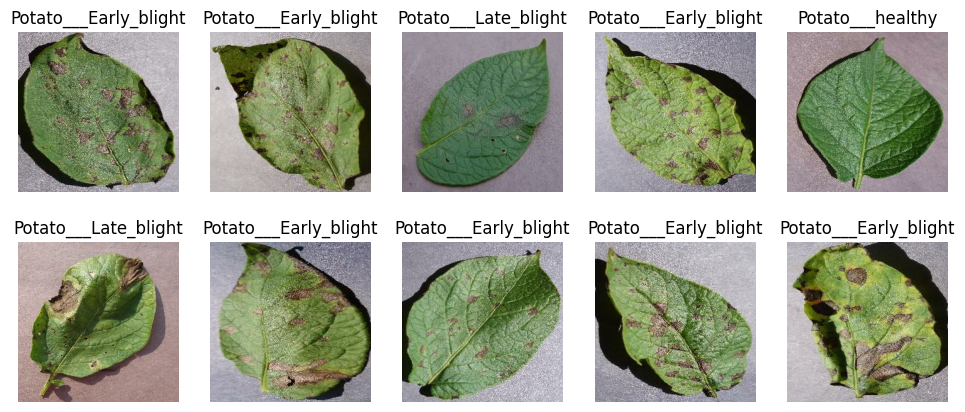

In [8]:
plt.figure(figsize=(12, 5))
for image_batch, label_batch in dataset.take(1):
    for i in range(10):
        plt.subplot(2,5,i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")

## 1.2- Data Spliting

In [ ]:
def split_data(ds, train_split=0.8, val_split=0.1, shuffle=True, shuffle_size=10000):
    
    if shuffle:
        ds.shuffle(shuffle_size, seed= 12)
    train_size = int(len(ds) * train_split)
    val_size = int(len(ds) * val_split)
    
    train_set = ds.take(train_size)
    val_set = ds.skip(train_size).take(val_size)
    test_set = ds.skip(train_size).skip(val_size)

    return train_set, val_set, test_set

In [ ]:
train_set, val_set, test_set = split_data(dataset, train_split=0.8, val_split=0.1)

print(f'train_set:    {len(train_set)*32} Images')
print(f'val_set:      {len(val_set)*32} Images')
print(f'test_set:     {len(test_set)*32} Images')

train_set:    1728 Images
val_set:      192 Images
test_set:     256 Images


In [13]:
train_set = train_set.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_set = train_set.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_set = train_set.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)

# 2- Model Building

In [14]:
resize_and_scale = [
    layers.Resizing(IMAGE_SIZE,IMAGE_SIZE),
    layers.Rescaling(1.0/255)
    ]

data_augmentation = [
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(height_factor=(-0.2, 0.2), width_factor=(-0.2, 0.2))
    ]

In [15]:
def build_features(input_shape):
    return [
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape = input_shape),
        layers.MaxPooling2D((2, 2))
        ]

def build_hidden_blocks(num_layers):
    block_layers = []
    for _ in range(num_layers):
        block_layers.append(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
        block_layers.append(layers.MaxPooling2D((2, 2)))
    return block_layers

def build_classifier(n_classes):
    return [
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation='softmax')
    ]

In [16]:
model = models.Sequential([
    layers.Input(shape=input_shape),
    *resize_and_scale,
    *data_augmentation,
    *build_features(input_shape),
    *build_hidden_blocks(5),
    *build_classifier(3)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 232,899 (909.76 KB)

 Trainable params: 232,899 (909.76 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# 3- Training

In [44]:
history = model.fit(
    train_set,
    epochs = EPOCHS,
    batch_size = BATCH_SIZE,
    verbose =1,
    validation_data = val_set
)

Epoch 1/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.9850 - loss: 0.0464 - val_accuracy: 0.9630 - val_loss: 0.0887
Epoch 2/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.9884 - loss: 0.0286 - val_accuracy: 0.9919 - val_loss: 0.0233
Epoch 3/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 84ms/step - accuracy: 0.9878 - loss: 0.0327 - val_accuracy: 0.9809 - val_loss: 0.0548
Epoch 4/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9931 - loss: 0.0172 - val_accuracy: 0.9959 - val_loss: 0.0120
Epoch 5/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9878 - loss: 0.0378 - val_accuracy: 0.9670 - val_loss: 0.1088
Epoch 6/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9948 - loss: 0.0156 - val_accuracy: 0.9838 - val_loss: 0.0497
Epoch 7/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.9919 - loss: 0.0203 - val_accuracy: 0.9907 - val_loss: 0.0295
Epoch 8/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.9913 - loss: 0.0305 - val_accuracy: 0.8906 - v

# 4- Evaluation

In [46]:
scores = model.evaluate(test_set)

54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9653 - loss: 0.1085


In [47]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

Text(0.5, 1.0, 'Train and Validation Loss')

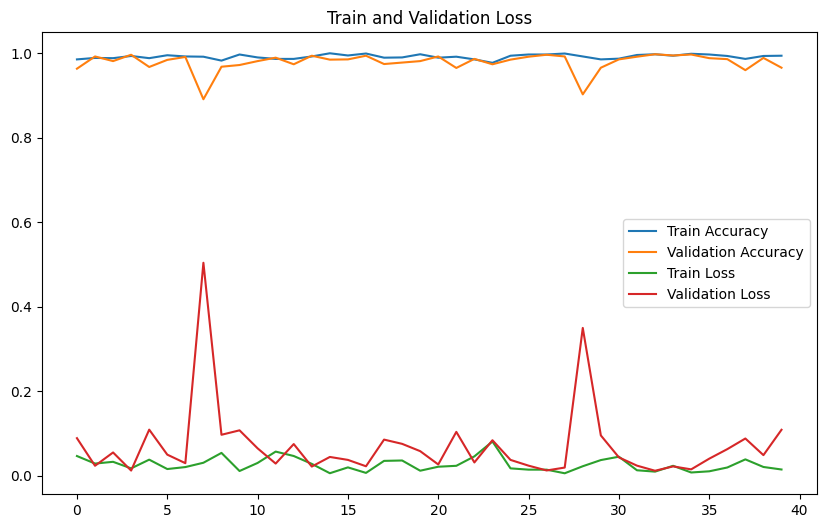

In [50]:
train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

train_loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(10,6))

plt.plot(range(EPOCHS), train_acc, label='Train Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Train and Validation Accuracy')

plt.plot(range(EPOCHS), train_loss, label='Train Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='right')
plt.title('Train and Validation Loss')

# 5- Saving

In [120]:
def model_name():
    model_version = [
    int(re.search(r'v(\d+)', f).group(1)) 
    for f in os.listdir(dir + "/models") 
    if re.search(r'v(\d+)', f)]
    
    return max(model_version, default=0) +1

In [132]:
model_version = model_name()
model.save(f"{dir}/models/model_v{model_version}.keras")

print(f"Saved: model_v{model_version}.keras\nAvailable models: {os.listdir(dir+"/models")}")

Saved: model_v1.keras
Available models: ['model_v1.keras']


# END